# Philippine Government Websites: Cleaning, Filtering and Shortlisting

**Goal:** narrow a list of 200+ `.gov.ph` websites down to **20-30 candidate reference websites** for research.

| Step | What happens | Output |
|---|---|---|
| 0 | Load and normalize the raw list | clean `domain`, `url`, sub-site flags |
| 1 | Keep **nationwide-use** websites only | drops regional / local / single-site entries |
| 2 | Remove **duplicates and unknown** entries | audit log of everything removed |
| 3 | **Categorize** by purpose | 13 purpose categories |
| 4 | **Validate** that sites are live | HTTP status, redirects, SSL, page title |
| 5 | **Shortlist** 20-30 candidates | transparent, adjustable scoring |
| 6 | Export | CSV files for the team |

> **Important:** scope, category and prominence score (Steps 1, 3, 5) are *judgment-based labels* stored in one editable table (Step 0b).
> They are a first pass for your team to review, not ground truth. Every removal is logged so you can reverse any decision.

In [52]:
import re
import time
import socket
import difflib
import concurrent.futures as cf
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

# ------------------------------ CONFIG: edit these ------------------------------
CSV_PATH         = r"C:\Users\geryl\OneDrive\Documents\HCI2000\WebsiteList.csv"   # path to the raw list
OUTPUT_DIR       = Path("output")
RUN_VALIDATION   = True     # Step 4 needs internet. Set False to skip.
FORCE_RECHECK    = False    # True = ignore cached validation results
TARGET_MIN, TARGET_MAX = 20, 30
PER_CATEGORY     = 2        # max picks per purpose category in the first selection pass
MIN_SCORE        = 3        # minimum prominence score (1-5) to be a candidate
EXCLUDE_CATEGORIES = {"OTH"}  # catch-all category is not used for the shortlist
# --------------------------------------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
funnel = []                       # tracks how many sites remain after each step
removed_log = []                  # audit trail: every removed row + reason

## Step 0: Load and normalize

Trim whitespace, lowercase domains, strip `http(s)://`, `www.` and trailing slashes, and detect **sub-sites** (e.g. `blr.dole.gov.ph` is a DOLE bureau, not a standalone agency).

In [53]:
raw = pd.read_csv(CSV_PATH, dtype=str).rename(columns={"No.": "no", "Website Name": "name", "Link": "domain"})
print("Raw shape:", raw.shape)
funnel.append(("Raw list", len(raw)))
raw.head()

Raw shape: (221, 3)


,no,name,domain
0,1,Agricultural Credit Policy Council,acpc.gov.ph
1,2,Al-Amanah Islamic Investment Bank of the Philippines,amanahbank.gov.ph
2,3,Anti-Money Laundering Council,amlc.gov.ph
3,4,Anti-Red Tape Authority,arta.gov.ph
4,5,"APO Production Unit, Inc.",apo.gov.ph


In [54]:
def clean_domain(x):
    x = "" if pd.isna(x) else str(x).strip().lower()
    x = re.sub(r"^https?://", "", x)
    x = x.split("/")[0].strip()
    return re.sub(r"^www\.", "", x)

def clean_name(x):
    return re.sub(r"\s+", " ", "" if pd.isna(x) else str(x)).strip()

df = raw.copy()
df["name"]   = df["name"].map(clean_name)
df["domain"] = df["domain"].map(clean_domain)
df["url"]    = "https://" + df["domain"]

# --- sub-site detection: x.parent.gov.ph  ->  parent.gov.ph
def parent_of(domain):
    core = re.sub(r"\.gov\.ph$", "", domain)
    core = re.sub(r"^(web|www)\.", "", core)          # web.nlp.gov.ph is just a host alias
    return core.split(".")[-1] + ".gov.ph" if "." in core else None

df["parent_domain"] = df["domain"].map(parent_of)
df["is_subsite"]    = df["parent_domain"].notna()
df["parent_in_list"] = df["parent_domain"].isin(set(df["domain"]))

print(f"{df.is_subsite.sum()} sub-sites detected; {(df.is_subsite & df.parent_in_list).sum()} of them have their parent agency in the list too.")
df[df.is_subsite][["name", "domain", "parent_domain", "parent_in_list"]]

20 sub-sites detected; 19 of them have their parent agency in the list too.


,name,domain,parent_domain,parent_in_list
18,Bureau of Labor Relations,blr.dole.gov.ph,dole.gov.ph,True
21,Bureau of Workers with Special Concerns,bwsc.dole.gov.ph,dole.gov.ph,True
22,Bureau of Working Conditions,bwc.dole.gov.ph,dole.gov.ph,True
69,Ecosystems Research Development Bureau,erdb.denr.gov.ph,denr.gov.ph,True
73,Fertilizer and Pesticide Authority,fpa.da.gov.ph,da.gov.ph,True
75,Forest Management Bureau,forestry.denr.gov.ph,denr.gov.ph,True
82,Institute for Labor Studies,ils.dole.gov.ph,dole.gov.ph,True
95,Maharlika Investment Corporation,maharlika.dof.gov.ph,dof.gov.ph,True
101,Movie and Television Review and Classification Board,midas.mtrcb.gov.ph,mtrcb.gov.ph,False
113,National Dairy Authority,nda.da.gov.ph,da.gov.ph,True


## Step 0b: Reference table (scope, purpose category, prominence score)

One row per website: `domain | category | scope | score`

* **scope**: `N` nationwide mandate/use, `R` regional / local / special economic zone / single-locality, `S` single facility (one hospital, one venue), `U` unknown
* **category**: purpose category code (legend below)
* **score** (1-5): my estimate of national prominence and citizen-facing relevance. This drives the shortlist in Step 5.

**Review this table.** Change any value and re-run the notebook from this cell down.

In [55]:
CATEGORIES = {
    "GOV": "Governance & Policy",
    "FIN": "Public Finance, Revenue & Procurement",
    "SOC": "Social Services & Welfare",
    "HLT": "Health",
    "EDU": "Education, Culture & Research",
    "LAB": "Labor & Employment",
    "JUS": "Justice, Law Enforcement & Security",
    "TRN": "Transport & Infrastructure",
    "TRD": "Trade, Industry, Tourism & Investment",
    "ENV": "Agriculture, Environment & Natural Resources",
    "ICT": "Information, Media & Communications",
    "REG": "Oversight & Regulation",
    "UTL": "Housing, Energy & Utilities",
    "OTH": "Other (sports, gaming, misc. GOCCs)",
}
SCOPES = {"N": "Nationwide", "R": "Regional / local / special zone", "S": "Single facility", "U": "Unknown"}

META_TEXT = """
acpc.gov.ph|ENV|N|2
amanahbank.gov.ph|FIN|N|1
amlc.gov.ph|REG|N|3
arta.gov.ph|REG|N|4
apo.gov.ph|OTH|N|1
apeco.gov.ph|TRD|R|2
afab.gov.ph|TRD|R|2
bsp.gov.ph|FIN|N|5
bcda.gov.ph|TRD|R|2
bmb.gov.ph|ENV|N|2
scouts.gov.ph|OTH|N|1
bcs.gov.ph|ICT|N|1
bucor.gov.ph|JUS|N|3
customs.gov.ph|FIN|N|4
bfp.gov.ph|JUS|N|4
immigration.gov.ph|JUS|N|4
bir.gov.ph|FIN|N|5
bjmp.gov.ph|JUS|N|3
blr.dole.gov.ph|LAB|N|2
blgf.gov.ph|FIN|N|2
treasury.gov.ph|FIN|N|4
bwsc.dole.gov.ph|LAB|N|1
bwc.dole.gov.ph|LAB|N|1
ceza.gov.ph|TRD|R|2
cesboard.gov.ph|GOV|N|2
cpa.gov.ph|TRN|R|2
citem.gov.ph|TRD|N|2
cbaa.gov.ph|FIN|N|1
caap.gov.ph|TRN|N|4
csc.gov.ph|REG|N|5
ciac.gov.ph|TRN|R|2
climate.gov.ph|ENV|N|3
coa.gov.ph|REG|N|5
comelec.gov.ph|REG|N|5
cfo.gov.ph|SOC|N|3
ched.gov.ph|EDU|N|4
chr.gov.ph|REG|N|4
popcom.gov.ph|SOC|N|2
cda.gov.ph|TRD|N|3
cwc.gov.ph|SOC|N|2
creditinfo.gov.ph|FIN|N|2
culturalcenter.gov.ph|EDU|S|2
cicc.gov.ph|ICT|N|3
ddb.gov.ph|JUS|N|2
dbp-leasing.gov.ph|FIN|N|1
dar.gov.ph|ENV|N|4
da.gov.ph|ENV|N|5
dbm.gov.ph|GOV|N|4
deped.gov.ph|EDU|N|5
doe.gov.ph|UTL|N|4
denr.gov.ph|ENV|N|5
dof.gov.ph|FIN|N|5
dfa.gov.ph|GOV|N|5
doh.gov.ph|HLT|N|5
dhsud.gov.ph|UTL|N|4
dict.gov.ph|ICT|N|5
doj.gov.ph|JUS|N|5
dole.gov.ph|LAB|N|5
dmw.gov.ph|LAB|N|4
dnd.gov.ph|JUS|N|4
dpwh.gov.ph|TRN|N|4
dost.gov.ph|EDU|N|5
dswd.gov.ph|SOC|N|5
dilg.gov.ph|GOV|N|5
tourism.gov.ph|TRD|N|4
dti.gov.ph|TRD|N|5
dotr.gov.ph|TRN|N|5
dutyfree.gov.ph|OTH|N|1
eccdcouncil.gov.ph|SOC|N|2
erdb.denr.gov.ph|ENV|N|2
ecc.gov.ph|LAB|N|2
erc.gov.ph|UTL|N|3
emb.gov.ph|ENV|N|3
fpa.da.gov.ph|ENV|N|2
fti.gov.ph|OTH|N|1
forestry.denr.gov.ph|ENV|N|2
gab.gov.ph|OTH|N|1
gcg.gov.ph|REG|N|2
gppb.gov.ph|GOV|N|3
gsis.gov.ph|SOC|N|4
pagibigfund.gov.ph|SOC|N|4
congress.gov.ph|GOV|N|4
ils.dole.gov.ph|LAB|N|1
insurance.gov.ph|REG|N|2
jjwc.gov.ph|SOC|N|1
kwf.gov.ph|EDU|N|3
llda.gov.ph|ENV|R|2
lmb.gov.ph|ENV|N|2
lra.gov.ph|JUS|N|4
ltfrb.gov.ph|TRN|N|3
lto.gov.ph|TRN|N|5
lrta.gov.ph|TRN|R|3
lwua.gov.ph|UTL|N|2
lcp.gov.ph|HLT|S|2
mciaa.gov.ph|TRN|R|2
maharlika.dof.gov.ph|FIN|N|2
miaa.gov.ph|TRN|R|3
mmda.gov.ph|GOV|R|3
mwss.gov.ph|UTL|R|3
minda.gov.ph|GOV|R|2
mgb.gov.ph|ENV|N|3
midas.mtrcb.gov.ph|ICT|N|2
napc.gov.ph|SOC|N|2
nationalarchives.gov.ph|EDU|N|3
nacc.gov.ph|SOC|N|2
nbi.gov.ph|JUS|N|5
ncca.gov.ph|EDU|N|3
ncsc.gov.ph|SOC|N|2
ncip.gov.ph|SOC|N|3
ncmf.gov.ph|SOC|N|2
ncmb.gov.ph|LAB|N|2
ncct.gov.ph|ICT|N|1
ncda.gov.ph|SOC|N|2
nda.da.gov.ph|ENV|N|2
ndc.gov.ph|TRD|N|2
neda.gov.ph|GOV|N|5
nea.gov.ph|UTL|N|3
nfa.gov.ph|ENV|N|3
nhcp.gov.ph|EDU|N|3
nhmfc.gov.ph|UTL|N|1
nha.gov.ph|UTL|N|3
nica.gov.ph|JUS|N|2
nia.gov.ph|ENV|N|3
nkti.gov.ph|HLT|S|2
nirc.dole.gov.ph|LAB|N|3
web.nlp.gov.ph|EDU|N|3
namria.gov.ph|ENV|N|3
nmis.gov.ph|ENV|N|2
nationalmuseum.gov.ph|EDU|N|3
napolcom.gov.ph|JUS|N|2
napocor.gov.ph|UTL|N|2
privacy.gov.ph|REG|N|4
nsc.gov.ph|JUS|N|3
ntrc.gov.ph|FIN|N|2
ntc.gov.ph|ICT|N|3
nta.da.gov.ph|ENV|N|2
nwpc.dole.gov.ph|LAB|N|3
nwrb.gov.ph|UTL|N|2
nyc.gov.ph|SOC|N|3
nrdc.denr.gov.ph|ENV|N|1
nayongpilipino.gov.ph|OTH|S|1
oshc.dole.gov.ph|LAB|N|2
ots.gov.ph|TRN|N|2
ogcc.gov.ph|REG|N|1
ombudsman.gov.ph|REG|N|5
op-proper.gov.ph|GOV|N|4
peace.gov.ph|GOV|N|2
osg.gov.ph|JUS|N|3
ovp.gov.ph|GOV|N|3
otc.gov.ph|TRN|N|1
omb.gov.ph|REG|N|1
pdgcc.gov.ph|OTH|S|1
pcsd.gov.ph|ENV|R|1
peatc.gov.ph|TRN|R|1
ptni.gov.ph|ICT|N|2
pcc.gov.ph|ENV|N|2
pced.gov.ph|EDU|N|1
philmech.gov.ph|ENV|N|2
pcso.gov.ph|OTH|N|3
pcmc.gov.ph|HLT|S|2
pca.gov.ph|ENV|N|2
pcw.gov.ph|SOC|N|3
phcc.gov.ph|REG|N|4
pcaf.da.gov.ph|ENV|N|2
pcic.gov.ph|FIN|N|2
pdic.gov.ph|FIN|N|4
pdea.gov.ph|JUS|N|3
peza.gov.ph|TRD|N|4
philfida.da.gov.ph|ENV|N|2
pfda.gov.ph|ENV|N|2
philgeps.gov.ph|FIN|N|4
philguarantee.gov.ph|FIN|N|1
philhealth.gov.ph|HLT|N|5
phc.gov.ph|HLT|S|2
pia.gov.ph|ICT|N|4
pids.gov.ph|EDU|N|4
pitahc.gov.ph|HLT|N|2
pitc.gov.ph|TRD|N|1
pmdc.gov.ph|ENV|N|1
pnp.gov.ph|JUS|N|5
pnr.gov.ph|TRN|R|2
pnvsca.gov.ph|SOC|N|1
pppi.gov.ph|HLT|N|1
phlpost.gov.ph|ICT|N|4
ppsc.gov.ph|JUS|N|2
philracom.gov.ph|OTH|N|1
pea.gov.ph|TRN|N|1
pra.gov.ph|TRD|N|2
philrice.gov.ph|ENV|N|3
prri.da.gov.ph|ENV|N|1
philsa.gov.ph|EDU|N|3
psc.gov.ph|OTH|N|3
doftaxacademy.gov.ph|FIN|N|1
piamo.gov.ph|TRD|R|1
poropointfreeport.gov.ph|TRD|R|1
psalm.gov.ph|UTL|N|1
rtvm.gov.ph|ICT|N|1
pcup.gov.ph|SOC|N|2
pcgg.gov.ph|JUS|N|1
pco.gov.ph|ICT|N|4
pllo.gov.ph|GOV|N|1
pms.gov.ph|GOV|N|2
pmo.gov.ph|FIN|N|1
ps-philgeps.gov.ph|FIN|N|2
prc.gov.ph|REG|N|5
pao.gov.ph|JUS|N|3
ppp.gov.ph|TRD|N|3
sec.gov.ph|REG|N|5
senate.gov.ph|GOV|N|4
shfc.dhsud.gov.ph|UTL|N|2
sss.gov.ph|SOC|N|5
spda.gov.ph|TRD|R|1
sra.gov.ph|ENV|N|2
tariffcommission.gov.ph|TRD|N|2
tesda.gov.ph|EDU|N|4
trb.gov.ph|TRN|N|2
tieza.gov.ph|TRD|N|2
tpb.gov.ph|TRD|N|2
unesco.gov.ph|EDU|N|2
buenosairespe.dfa.gov.ph|GOV|U|0
zfa.gov.ph|TRD|R|1
"""

meta = pd.DataFrame(
    [ln.split("|") for ln in META_TEXT.strip().splitlines()],
    columns=["domain", "category", "scope", "score"],
)
meta["score"] = meta["score"].astype(int)

df = df.merge(meta, on="domain", how="left")
unmapped = df[df["category"].isna()]
if len(unmapped):
    print("WARNING: these rows have no entry in the reference table (scope=Unknown):")
    display(unmapped[["no", "name", "domain"]])
    df["scope"] = df["scope"].fillna("U")
    df["category"] = df["category"].fillna("OTH")
    df["score"] = df["score"].fillna(0).astype(int)

df["category_name"] = df["category"].map(CATEGORIES)
df["scope_name"]    = df["scope"].map(SCOPES)
df.groupby("scope_name").size().rename("sites").to_frame()

,sites
scope_name,
Nationwide,193
Regional / local / special zone,20
Single facility,7
Unknown,1


## Step 1: Keep nationwide-use websites only

Removed here: regional authorities, economic zones / freeports, single airports and ports, Metro Manila-only agencies, and single-site facilities (individual hospitals, venues).
Entries with unknown scope are kept for now and handled in Step 2.

In [56]:
is_local = df["scope"].isin(["R", "S"])

removed = df[is_local].assign(reason=lambda d: "Not nationwide: " + d["scope_name"])
removed_log.append(removed)

df1 = df[~is_local].copy()
funnel.append(("After Step 1: nationwide only", len(df1)))

print(f"Removed {len(removed)} non-nationwide sites, {len(df1)} remain.\n")
removed[["name", "domain", "scope_name"]].reset_index(drop=True)

Removed 27 non-nationwide sites, 194 remain.



,name,domain,scope_name
0,Aurora Pacific Economic Zone and Freeport Authority,apeco.gov.ph,Regional / local / special zone
1,Authority of the Freeport Area of Bataan,afab.gov.ph,Regional / local / special zone
2,Bases Conversion and Development Authority,bcda.gov.ph,Regional / local / special zone
3,Cagayan Economic Zone Authority,ceza.gov.ph,Regional / local / special zone
4,Cebu Port Authority,cpa.gov.ph,Regional / local / special zone
5,Clark International Airport Corporation,ciac.gov.ph,Regional / local / special zone
6,Cultural Center of the Philippines,culturalcenter.gov.ph,Single facility
7,Laguna Lake Development Authority,llda.gov.ph,Regional / local / special zone
8,Light Rail Transit Authority,lrta.gov.ph,Regional / local / special zone
9,Lung Center of the Philippines,lcp.gov.ph,Single facility


## Step 2: Remove duplicates and unknown entries

Checks, in this order:
1. **Unknown / unverifiable:** blank or placeholder names ("Unknown Entry"), missing domains, non-`.gov.ph` domains, and DFA foreign-post (embassy/consulate) subdomains
2. **Exact duplicates:** same normalized domain
3. **Duplicate names:** same normalized name under a different domain

Then a **fuzzy check** prints near-duplicate names and shared-parent groups for **manual review** (nothing is removed automatically there).

In [57]:
def norm_name(s):
    s = re.sub(r"[^a-z0-9 ]", " ", s.lower())
    s = re.sub(r"\b(the|inc|incorporated|of)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df2 = df1.copy()
df2["name_key"] = df2["name"].map(norm_name)

# 1) unknown / unverifiable
unknown_mask = (
    df2["name"].str.contains(r"unknown|n/?a\b|tbd|^$", case=False, regex=True)
    | df2["domain"].eq("")
    | ~df2["domain"].str.endswith(".gov.ph")
    | df2["domain"].str.contains(r"\.dfa\.gov\.ph$")
)
rm_unknown = df2[unknown_mask].assign(reason="Unknown / unverifiable entry")
df2 = df2[~unknown_mask]

# 2) exact duplicate domains (keep first occurrence)
dup_domain = df2.duplicated("domain", keep="first")
rm_dupd = df2[dup_domain].assign(reason="Duplicate domain")
df2 = df2[~dup_domain]

# 3) duplicate names (keep first occurrence)
dup_name = df2.duplicated("name_key", keep="first")
rm_dupn = df2[dup_name].assign(reason="Duplicate name")
df2 = df2[~dup_name]

removed_log.extend([rm_unknown, rm_dupd, rm_dupn])
funnel.append(("After Step 2: no duplicates/unknowns", len(df2)))

print(f"Unknown/unverifiable: {len(rm_unknown)} | Duplicate domains: {len(rm_dupd)} | Duplicate names: {len(rm_dupn)}")
print(f"{len(df2)} sites remain.\n")
pd.concat([rm_unknown, rm_dupd, rm_dupn])[["no", "name", "domain", "reason"]].reset_index(drop=True)

Unknown/unverifiable: 1 | Duplicate domains: 0 | Duplicate names: 0
193 sites remain.



,no,name,domain,reason
0,220,Unknown Entry,buenosairespe.dfa.gov.ph,Unknown / unverifiable entry


In [58]:
# --- Manual review aid 1: near-duplicate names (not auto-removed) ---
keys = df2[["name", "domain", "name_key"]].reset_index(drop=True)
pairs = []
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        r = difflib.SequenceMatcher(None, keys.name_key[i], keys.name_key[j]).ratio()
        if r >= 0.85:
            pairs.append((round(r, 2), keys.name[i], keys.domain[i], keys.name[j], keys.domain[j]))
print("Near-duplicate name pairs (>= 0.85 similarity):")
pd.DataFrame(pairs, columns=["similarity", "name_a", "domain_a", "name_b", "domain_b"]) if pairs else print("  none found")

Near-duplicate name pairs (>= 0.85 similarity):


,similarity,name_a,domain_a,name_b,domain_b
0,0.85,National Dairy Authority,nda.da.gov.ph,National Food Authority,nfa.gov.ph
1,0.87,National Police Commission,napolcom.gov.ph,National Privacy Commission,privacy.gov.ph
2,0.86,Office of the President,op-proper.gov.ph,Office of the Vice President,ovp.gov.ph
3,0.88,Philippine Crop Insurance Corporation,pcic.gov.ph,Philippine Deposit Insurance Corporation,pdic.gov.ph
4,0.87,Philippine Crop Insurance Corporation,pcic.gov.ph,Philippine Health Insurance Corporation,philhealth.gov.ph
5,0.89,Philippine Deposit Insurance Corporation,pdic.gov.ph,Philippine Health Insurance Corporation,philhealth.gov.ph
6,0.88,Philippine Fiber Industry Development Authority,philfida.da.gov.ph,Philippine Fisheries Development Authority,pfda.gov.ph
7,0.91,Philippine Rice Research Institute,philrice.gov.ph,Philippine Rubber Research Institute,prri.da.gov.ph


In [59]:
# --- Manual review aid 2: sites that share a parent agency (consolidation candidates) ---
groups = (
    df2[df2["parent_in_list"]]
    .groupby("parent_domain")["domain"].apply(list)
    .rename("sub-sites in list")
    .to_frame()
)
groups

,sub-sites in list
parent_domain,
da.gov.ph,"[fpa.da.gov.ph, nda.da.gov.ph, nta.da.gov.ph, pcaf.da.gov.ph, phil..."
denr.gov.ph,"[erdb.denr.gov.ph, forestry.denr.gov.ph, nrdc.denr.gov.ph]"
dhsud.gov.ph,[shfc.dhsud.gov.ph]
dof.gov.ph,[maharlika.dof.gov.ph]
dole.gov.ph,"[blr.dole.gov.ph, bwsc.dole.gov.ph, bwc.dole.gov.ph, ils.dole.gov...."


**Sub-site policy:** sub-sites whose parent agency is also in the list (e.g. DOLE bureaus, DENR / DA attached agencies) stay in the cleaned dataset, but are **excluded from the shortlist** in Step 5. One parent site usually represents the whole agency for reference purposes. Set `parent_in_list` handling in Step 5 if you want them back.

## Step 3: Categorize by purpose

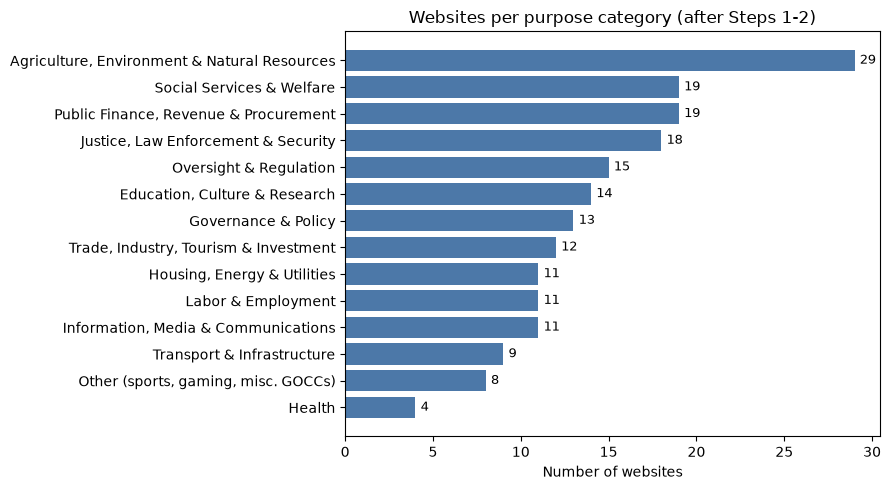

,category,category_name,sites
0,ENV,"Agriculture, Environment & Natural Resources",29
1,FIN,"Public Finance, Revenue & Procurement",19
2,SOC,Social Services & Welfare,19
3,JUS,"Justice, Law Enforcement & Security",18
4,REG,Oversight & Regulation,15
5,EDU,"Education, Culture & Research",14
6,GOV,Governance & Policy,13
7,TRD,"Trade, Industry, Tourism & Investment",12
8,ICT,"Information, Media & Communications",11
9,LAB,Labor & Employment,11


In [60]:
df3 = df2.copy()

summary = (
    df3.groupby(["category", "category_name"]).size()
       .rename("sites").reset_index()
       .sort_values("sites", ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(summary["category_name"], summary["sites"], color="#4C78A8")
for y, v in enumerate(summary["sites"]):
    ax.text(v + 0.3, y, str(v), va="center", fontsize=9)
ax.set_xlabel("Number of websites")
ax.set_title("Websites per purpose category (after Steps 1-2)")
plt.tight_layout()
plt.show()

summary.sort_values("sites", ascending=False).reset_index(drop=True)

In [61]:
# Browse any category: change the code, e.g. "FIN", "HLT", "ICT"
CATEGORY_TO_BROWSE = "SOC"
df3[df3.category == CATEGORY_TO_BROWSE].sort_values("score", ascending=False)[["name", "domain", "score", "is_subsite"]]

,name,domain,score,is_subsite
62,Department of Social Welfare and Development,dswd.gov.ph,5,False
210,Social Security System,sss.gov.ph,5,False
80,Home Development Mutual Fund (PAG-IBIG),pagibigfund.gov.ph,4,False
79,Government Service Insurance System,gsis.gov.ph,4,False
138,National Youth Commission,nyc.gov.ph,3,False
34,Commission on Filipinos Overseas,cfo.gov.ph,3,False
161,Philippine Commission on Women,pcw.gov.ph,3,False
108,National Commission on Indigenous Peoples,ncip.gov.ph,3,False
37,Commission on Population and Development,popcom.gov.ph,2,False
39,Council for the Welfare of Children,cwc.gov.ph,2,False


## Step 4: Validate that the sites are live

For each remaining site this checks: **DNS resolution**, **HTTP status** (HTTPS first, then HTTP fallback), **SSL certificate problems**, **redirects** to a different domain, and the **page `<title>`** (so you can eyeball whether the site matches its listed name).

* Requires internet access. Run from a Philippine network if possible, since some `.gov.ph` sites throttle or block foreign traffic.
* Status `403` / `429` usually means the site is up but blocks scripts, so it is classed as *reachable (blocks bots)*, not dead.
* Results are cached to `output/validation_results.csv`, so re-runs are instant unless `FORCE_RECHECK = True`.

In [62]:
import requests, urllib3
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml",
}

def reg_domain(host):
    host = re.sub(r"^www\.", "", (host or "").lower())
    parts = host.split(".")
    return ".".join(parts[-3:]) if host.endswith(".gov.ph") else host

def check_site(domain, timeout=12):
    out = dict(domain=domain, dns_ok=False, status=None, final_url=None,
               ssl_issue=False, response_s=None, title=None, error=None)
    try:
        socket.gethostbyname(domain)
        out["dns_ok"] = True
    except Exception as e:
        out["error"] = f"DNS: {type(e).__name__}"
        return out

    for scheme in ("https", "http"):
        for verify in ((True, False) if scheme == "https" else (False,)):
            try:
                t0 = time.time()
                r = requests.get(f"{scheme}://{domain}", headers=HEADERS, timeout=timeout,
                                 allow_redirects=True, verify=verify)
                out.update(status=r.status_code, final_url=r.url,
                           ssl_issue=(scheme == "https" and not verify),
                           response_s=round(time.time() - t0, 2), error=None)
                html = r.content[:60000].decode(r.encoding or "utf-8", "ignore")
                m = re.search(r"<title[^>]*>(.*?)</title>", html, re.I | re.S)
                if m:
                    out["title"] = " ".join(m.group(1).split())[:120]
                return out
            except requests.exceptions.SSLError:
                out["error"] = "SSLError"
                continue                       # retry same scheme without verification
            except Exception as e:
                out["error"] = type(e).__name__
                break                          # try next scheme
    return out

def classify(row):
    if not row["dns_ok"]:
        return "down (DNS fails)"
    if pd.isna(row["status"]):
        return "down (no response)"
    s = int(row["status"])
    if s < 400:
        return "ok"
    if s in (401, 403, 429):
        return "reachable (blocks bots)"
    return f"error (HTTP {s})"

cache_file = OUTPUT_DIR / "validation_results.csv"

if RUN_VALIDATION:
    if cache_file.exists() and not FORCE_RECHECK:
        val = pd.read_csv(cache_file)
        print(f"Loaded cached results for {len(val)} sites from {cache_file}")
    else:
        domains = df3["domain"].tolist()
        print(f"Checking {len(domains)} sites (this can take 1-3 minutes)...")
        with cf.ThreadPoolExecutor(max_workers=16) as ex:
            val = pd.DataFrame(list(ex.map(check_site, domains)))
        val.to_csv(cache_file, index=False)
    val["status_class"] = val.apply(classify, axis=1)
    val["redirected_offsite"] = val["final_url"].map(lambda u: reg_domain(urlparse(u).netloc) if isinstance(u, str) else None)
    val["redirected_offsite"] = val.apply(
        lambda r: bool(r["redirected_offsite"]) and r["redirected_offsite"] != reg_domain(r["domain"]), axis=1)
    df4 = df3.merge(val, on="domain", how="left")
else:
    df4 = df3.copy()
    df4["status_class"] = "not checked"
    df4["title"] = None
    df4["redirected_offsite"] = False
    df4["ssl_issue"] = False
    df4["final_url"] = None
    df4["error"] = None
    print("Validation skipped (RUN_VALIDATION = False).")

funnel.append(("After Step 4: validated list (no sites dropped yet)", len(df4)))
df4["status_class"].value_counts().rename("sites").to_frame()

Checking 193 sites (this can take 1-3 minutes)...


,sites
status_class,
ok,91
reachable (blocks bots),80
down (DNS fails),15
down (no response),5
error (HTTP 404),2


In [63]:
# Sites needing attention: not OK, SSL problems, or redirected to another domain
problems = df4[
    ~df4["status_class"].isin(["ok", "not checked"])
    | df4["ssl_issue"].fillna(False)
    | df4["redirected_offsite"].fillna(False)
][["name", "domain", "status_class", "ssl_issue", "redirected_offsite", "final_url", "error"]]
problems.reset_index(drop=True)

,name,domain,status_class,ssl_issue,redirected_offsite,final_url,error
0,Al-Amanah Islamic Investment Bank of the Philippines,amanahbank.gov.ph,reachable (blocks bots),False,False,https://amanahbank.gov.ph/,NaN
1,Anti-Red Tape Authority,arta.gov.ph,reachable (blocks bots),False,False,https://arta.gov.ph/,NaN
2,Bangko Sentral ng Pilipinas,bsp.gov.ph,down (DNS fails),False,True,NaN,DNS: gaierror
3,Biodiversity Management Bureau,bmb.gov.ph,reachable (blocks bots),False,False,https://bmb.gov.ph/,NaN
4,Boy Scouts of the Philippines,scouts.gov.ph,reachable (blocks bots),False,False,https://scouts.gov.ph/,NaN
5,Bureau of Communications Services,bcs.gov.ph,reachable (blocks bots),False,False,https://bcs.gov.ph/,NaN
6,Bureau of Fire Protection,bfp.gov.ph,reachable (blocks bots),False,False,https://bfp.gov.ph/,NaN
7,Bureau of Internal Revenue,bir.gov.ph,down (DNS fails),False,True,NaN,DNS: gaierror
8,Bureau of Jail Management and Penology,bjmp.gov.ph,reachable (blocks bots),False,False,https://bjmp.gov.ph/,NaN
9,Bureau of Labor Relations,blr.dole.gov.ph,reachable (blocks bots),False,False,https://blr.dole.gov.ph/,NaN


In [64]:
def tokens(s):
    stop = {
        "of", "the", "and", "for", "philippines", "philippine",
        "national", "department", "bureau", "office",
        "commission", "authority", "corporation", "republic",
        "gov", "ph", "official", "website"
    }

    # Handle missing values and non-string values
    if not isinstance(s, str):
        if pd.isna(s):
            return set()
        s = str(s)

    words = re.findall(r"[a-z]{3,}", s.lower())

    return {w for w in words if w not in stop}

print(tokens("Department of Education"))
print(tokens(None))
print(tokens(float("nan")))
print(tokens(123))

{'education'}
set()
set()
set()


## Step 5: Shortlist 20-30 candidates

**Method (transparent and adjustable):**
1. Candidate pool = nationwide, non-duplicate, **live** sites, excluding sub-sites whose parent is already in the list, with `score >= MIN_SCORE` and not in `EXCLUDE_CATEGORIES` (the catch-all "Other" group).
2. Within each purpose category, rank by prominence `score` (ties broken alphabetically) and take the top `PER_CATEGORY`. This keeps the shortlist **diverse across purposes**.
3. If that gives fewer than `TARGET_MIN`, fill the remaining slots with the next-best sites overall. If more than `TARGET_MAX`, keep the highest scored.
4. Use `FORCE_INCLUDE` / `FORCE_EXCLUDE` (by domain) for manual overrides based on your research needs.

In [65]:
FORCE_INCLUDE = set({"sss.gov.ph", "pcso.gov.ph", "lto.gov.ph", "bir.gov.ph", "prc.gov.ph",
                     "csc.gov.ph", "philhealth.gov.ph", "nbi.gov.ph", "deped.gov.ph", "dost.gov.ph", 
                     "pagibigfund.gov.ph", "tesda.gov.ph", "e-tesda.gov.ph", "passport.gov.ph"})    # e.g. {"dfa.gov.ph"}    # e.g. {"senate.gov.ph", "pnp.gov.ph"}
FORCE_EXCLUDE = set() 

pool = df4[
    ~(df4["is_subsite"] & df4["parent_in_list"])
    & ~df4["status_class"].str.startswith(("down", "error"))
    & (df4["score"] >= MIN_SCORE)
    & ~df4["category"].isin(EXCLUDE_CATEGORIES)
    & ~df4["domain"].isin(FORCE_EXCLUDE)
].sort_values(["score", "name"], ascending=[False, True])

picked = pool.groupby("category", group_keys=False).head(PER_CATEGORY)

if len(picked) < TARGET_MIN:
    extra = pool.drop(picked.index).head(TARGET_MIN - len(picked))
    picked = pd.concat([picked, extra])

forced = df4[df4["domain"].isin(FORCE_INCLUDE)]
picked = pd.concat([picked, forced]).drop_duplicates("domain")

if len(picked) > TARGET_MAX:
    keep_forced = picked[picked["domain"].isin(FORCE_INCLUDE)]
    rest = picked[~picked["domain"].isin(FORCE_INCLUDE)].sort_values("score", ascending=False)
    picked = pd.concat([keep_forced, rest]).head(TARGET_MAX)

shortlist = picked.sort_values(["category_name", "score", "name"], ascending=[True, False, True]).reset_index(drop=True)
funnel.append(("Final shortlist", len(shortlist)))

print(f"Shortlist size: {len(shortlist)} (target {TARGET_MIN}-{TARGET_MAX})")
shortlist[["category_name", "name", "domain", "score", "status_class"]]

Shortlist size: 30 (target 20-30)


,category_name,name,domain,score,status_class
0,"Agriculture, Environment & Natural Resources",Department of Agriculture,da.gov.ph,5,ok
1,"Agriculture, Environment & Natural Resources",Department of Environment and Natural Resources,denr.gov.ph,5,reachable (blocks bots)
2,"Education, Culture & Research",Department of Education,deped.gov.ph,5,ok
3,"Education, Culture & Research",Department of Science and Technology,dost.gov.ph,5,ok
4,"Education, Culture & Research",Technical Education and Skills Development Authority,tesda.gov.ph,4,ok
5,Governance & Policy,Department of Foreign Affairs,dfa.gov.ph,5,reachable (blocks bots)
6,Governance & Policy,Department of the Interior and Local Government,dilg.gov.ph,5,ok
7,Health,Department of Health,doh.gov.ph,5,reachable (blocks bots)
8,Health,Philippine Health Insurance Corporation,philhealth.gov.ph,5,down (DNS fails)
9,"Housing, Energy & Utilities",Department of Energy,doe.gov.ph,4,ok


In [66]:
# Funnel summary and category coverage
display(pd.DataFrame(funnel, columns=["stage", "sites remaining"]))
display(shortlist.groupby("category_name").size().rename("picked").to_frame())

# Strong candidates that did NOT make the cut (useful for swapping in/out)
near_miss = pool[~pool["domain"].isin(shortlist["domain"])].head(15)
print("Next-best candidates not selected:")
near_miss[["category_name", "name", "domain", "score"]].reset_index(drop=True)

,stage,sites remaining
0,Raw list,221
1,After Step 1: nationwide only,194
2,After Step 2: no duplicates/unknowns,193
3,After Step 4: validated list (no sites dropped yet),193
4,Final shortlist,30


,picked
category_name,
"Agriculture, Environment & Natural Resources",2
"Education, Culture & Research",3
Governance & Policy,2
Health,2
"Housing, Energy & Utilities",2
"Information, Media & Communications",1
"Justice, Law Enforcement & Security",2
Labor & Employment,2
"Other (sports, gaming, misc. GOCCs)",1


Next-best candidates not selected:


,category_name,name,domain,score
0,Oversight & Regulation,Commission on Elections,comelec.gov.ph,5
1,Oversight & Regulation,Office of the Ombudsman,ombudsman.gov.ph,5
2,"Justice, Law Enforcement & Security",Philippine National Police,pnp.gov.ph,5
3,Oversight & Regulation,Securities and Exchange Commission,sec.gov.ph,5
4,Oversight & Regulation,Anti-Red Tape Authority,arta.gov.ph,4
5,"Justice, Law Enforcement & Security",Bureau of Fire Protection,bfp.gov.ph,4
6,"Justice, Law Enforcement & Security",Bureau of Immigration,immigration.gov.ph,4
7,Transport & Infrastructure,Civil Aviation Authority of the Philippines,caap.gov.ph,4
8,"Education, Culture & Research",Commission on Higher Education,ched.gov.ph,4
9,Oversight & Regulation,Commission on Human Rights,chr.gov.ph,4


## Step 6: Export

In [67]:
log = pd.concat(removed_log, ignore_index=True)[["no", "name", "domain", "reason"]]

df4.drop(columns=["name_key"], errors="ignore").to_csv(OUTPUT_DIR / "cleaned_categorized_all.csv", index=False)
shortlist.drop(columns=["name_key"], errors="ignore").to_csv(OUTPUT_DIR / "shortlist_candidates.csv", index=False)
log.to_csv(OUTPUT_DIR / "removed_log.csv", index=False)

print("Saved to", OUTPUT_DIR.resolve())
for f in sorted(OUTPUT_DIR.iterdir()):
    print(" -", f.name)

Saved to C:\Users\geryl\Downloads\output
 - cleaned_categorized_all.csv
 - removed_log.csv
 - shortlist_candidates.csv
 - validation_results.csv
